#### 从评论看痛点：亚马逊手机壳低评分与用户反馈分析（完整复现 Notebook）
1. **数据清洗与质量核验**：读取 `卖家评论.xlsx`（工作表 `B0FH655984-Review(1190)`），校核唯一评论 ID、星级、日期、图片标记与型号 Size。
2. **统计估计与假设检验**：复算低评分比例（Wilson 95% 区间）、图片标记列联表、两组比例差（Newcombe 95% 区间）、比例比与优势比（log-Wald 区间）、未校正 Pearson $\chi^2$ 检验及双侧 Fisher 精确检验。
3. **稳健性与分层检查**：复算正文规范化去重、仅 1 星阈值、排除 3 星、仅 7—8 月样本，以及按月/按手机型号 Size 的 Cochran–Mantel–Haenszel (CMH) 分层检验。
4. **文本规则匹配与敏感性比较**：加载 37 条中英文关键词正则规则，计算 407 条低星评论中 5 类负向规则命中率及“仅原文”敏感性对比。

> **运行模式说明**：
> - **完整复现模式**：将原始 `卖家评论.xlsx` 放在指定路径（默认 `./卖家评论.xlsx`），按顺序运行全部单元格即可从零重算并导出全部 CSV / JSON 与图表。
> - **图表复现模式**：读取 `数据结果/统计结果.json`，第 5 节绘图代码可直接渲染四张高清报告图。

##### 1. 环境配置、路径设置与全局图表配色定义

In [18]:
import hashlib
import html
import json
import math
import platform
import re
from pathlib import Path
from statistics import NormalDist
from urllib.parse import parse_qs, urlparse

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# ==================== 1. 路径配置（按需修改） ====================
EXCEL_PATH = Path("卖家评论.xlsx")          # 原始 Excel 文件路径
RULES_PATH = Path("主题规则.json")          # 关键词规则文件路径（若不存在则自动使用内置规则）
OUT_DIR = Path("数据结果")                  # 统计结果 CSV/JSON 输出目录
CHART_DIR = Path("图表")                    # 图表 PNG/SVG 输出目录

OUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

# ==================== 2. 全局配色常量（严格对齐 生成图表.py） ====================
PALETTE = {
    "BLACK":  "#17212C",  # 主标题、柱顶/点旁数值标签、坐标刻度标签
    "GRAY":   "#526171",  # 副标题、轴说明、坐标数字、页脚注释
    "GRID":   "#E3E8ED",  # 辅助网格线、页脚分隔线
    "BLUE":   "#2463A8",  # 3—5星柱形、未标记图片组点与区间、低星主题横向条形
    "ORANGE": "#C96822",  # 1—2星低评分柱形、有图片标记组点与区间
    "WHITE":  "#FFFFFF",  # 画布背景色、散点描边色
}

# ==================== 3. 中文字体自动适配 ====================
def setup_chinese_font():
    candidates = [
        "PingFang SC", "Hiragino Sans GB", "Heiti SC", "Arial Unicode MS",
        "Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "WenQuanYi Micro Hei"
    ]
    available = {f.name for f in fm.fontManager.ttflist}
    chosen = [f for f in candidates if f in available]
    if chosen:
        plt.rcParams["font.sans-serif"] = chosen + ["DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    return chosen[0] if chosen else "Default"

active_font = setup_chinese_font()

##### 2. 统计检验与数据清洗核心函数

所有数学定义：
- **Wilson 95% 置信区间**：单组二项比例估计。
- **Newcombe 混合得分区间**：未作连续性校正的两组比例差区间。
- **双侧 Fisher 精确检验**：固定边际下“超几何概率不大于观测表概率”的双侧定义（与 `scipy.stats.fisher_exact` 数值一致）。
- **Cochran–Mantel–Haenszel (CMH) 分层检验**：计算跨月份与跨手机型号 Size 的汇总优势比（Common Odds Ratio）。

In [19]:
Z = NormalDist().inv_cdf(0.975)

def wilson(k, n):
    if not n:
        return [None, None]
    p = k / n
    center = (p + Z * Z / (2 * n)) / (1 + Z * Z / n)
    half = Z * math.sqrt(p * (1 - p) / n + Z * Z / (4 * n * n)) / (1 + Z * Z / n)
    return [max(0.0, center - half), min(1.0, center + half)]

def fisher_two_sided(a, b, c, d):
    '''固定边际下超几何概率 <= 观测表概率的双侧精确检验。'''
    n = a + b + c + d
    r = a + b
    k = a + c
    def lc(nn, kk):
        return math.lgamma(nn + 1) - math.lgamma(kk + 1) - math.lgamma(nn - kk + 1)
    def logp(x):
        return lc(k, x) + lc(n - k, r - x) - lc(n, r)
    observed = logp(a)
    vals = [
        math.exp(logp(x))
        for x in range(max(0, r - (n - k)), min(r, k) + 1)
        if logp(x) <= observed + 1e-10
    ]
    return min(1.0, math.fsum(vals))

def comparison(df, cutoff=2):
    x = df["image_marked"].astype(bool)
    y = df["rating"].le(cutoff)
    a = int((x & y).sum())
    b = int((x & ~y).sum())
    c = int((~x & y).sum())
    d = int((~x & ~y).sum())
    n1 = a + b
    n0 = c + d
    n = n1 + n0
    if not n1 or not n0:
        return {"n": n, "table": [[a, b], [c, d]], "estimable": False}
    p1 = a / n1
    p0 = c / n0
    diff = p1 - p0
    l1, u1 = wilson(a, n1)
    l0, u0 = wilson(c, n0)
    # Newcombe 混合得分区间（无连续性校正）
    diff_ci = [
        diff - math.sqrt((p1 - l1) ** 2 + (u0 - p0) ** 2),
        diff + math.sqrt((u1 - p1) ** 2 + (p0 - l0) ** 2),
    ]
    expected = np.outer([n1, n0], [a + c, b + d]) / n
    observed = np.array([[a, b], [c, d]], dtype=float)
    chi = float(((observed - expected) ** 2 / expected).sum()) if (expected > 0).all() else None
    result = {
        "n": n,
        "table": [[a, b], [c, d]],
        "estimable": True,
        "image_rate": p1,
        "unmarked_rate": p0,
        "image_wilson95": [l1, u1],
        "unmarked_wilson95": [l0, u0],
        "difference": diff,
        "difference_newcombe95": diff_ci,
        "fisher_p": fisher_two_sided(a, b, c, d),
        "pearson_chi2": chi,
        "pearson_df": 1,
        "pearson_p": math.erfc(math.sqrt(chi / 2)) if chi is not None else None,
        "minimum_expected": float(expected.min()),
    }
    if min(a, b, c, d) > 0:
        rr = p1 / p0
        rr_se = math.sqrt(1 / a - 1 / n1 + 1 / c - 1 / n0)
        odds = a * d / (b * c)
        or_se = math.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
        result.update(
            ratio=rr,
            ratio_log95=[math.exp(math.log(rr) - Z * rr_se), math.exp(math.log(rr) + Z * rr_se)],
            odds_ratio=odds,
            odds_ratio_log95=[math.exp(math.log(odds) - Z * or_se), math.exp(math.log(odds) + Z * or_se)],
        )
    return result

def cmh(tables):
    total_num = total_den = delta = variance = 0.0
    valid = 0
    for t in tables:
        a, b = t[0]
        c, d = t[1]
        n = a + b + c + d
        if n <= 1 or not (a + b) * (c + d) * (a + c) * (b + d):
            continue
        valid += 1
        total_num += a * d / n
        total_den += b * c / n
        delta += a - (a + b) * (a + c) / n
        variance += (a + b) * (c + d) * (a + c) * (b + d) / (n * n * (n - 1))
    chi = delta * delta / variance if variance else None
    return {
        "informative_strata": valid,
        "common_odds_ratio": total_num / total_den if total_den else None,
        "cmh_chi2_no_correction": chi,
        "cmh_p": math.erfc(math.sqrt(chi / 2)) if chi is not None else None,
    }

def plain(v):
    if pd.isna(v):
        return ""
    v = re.sub(r"<br\s*/?>", ". ", str(v), flags=re.I)
    v = re.sub(r"<[^>]+>", " ", v)
    return re.sub(r"\s+", " ", html.unescape(v)).strip().strip(".").strip()

def parse_source(path: Path):
    xls = pd.ExcelFile(path)
    raw = pd.read_excel(xls, sheet_name=0)
    required = ["型号", "标题", "标题 (翻译)", "内容", "内容(翻译)", "星级", "图片数量", "评论时间", "链接"]
    missing = set(required) - set(raw.columns)
    if missing:
        raise ValueError(f"缺少必要列: {missing}")
    df = raw.copy()
    df["source_row"] = range(2, len(df) + 2)
    df["review_id"] = df["链接"].str.extract(r"/customer-reviews/([^/?]+)", expand=False)
    if df.review_id.isna().any():
        raise ValueError("存在无法解析的评论 ID")
    conflicting = df.groupby("review_id")[required].nunique(dropna=False).gt(1).any(axis=1)
    if conflicting.any():
        raise ValueError("存在内容冲突的重复评论 ID")
    df = df.drop_duplicates("review_id").copy()
    df["rating"] = pd.to_numeric(df["星级"], errors="coerce")
    df["date"] = pd.to_datetime(df["评论时间"], errors="coerce")
    if (~df.rating.isin([1, 2, 3, 4, 5])).any() or df.date.isna().any():
        raise ValueError("存在无效星级或日期")
    pic = pd.to_numeric(df["图片数量"], errors="coerce")
    if pic.lt(0).any():
        raise ValueError("图片数量为负数")
    df["image_marked"] = pic.gt(0)
    df["image_count_missing"] = pic.isna()
    df["low_rating"] = df.rating.le(2)
    df["month"] = df.date.dt.strftime("%Y-%m")
    for col, target in [("标题", "title"), ("标题 (翻译)", "title_translation"), ("内容", "body"), ("内容(翻译)", "translation")]:
        df[target] = df[col].map(plain)
    df["body_normalized"] = df.body.str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
    df["model"] = df["型号"].map(plain)
    df["size"] = (
        df.model.str.extract(r"Size:\s*(.*)", expand=False)
        .fillna("未识别")
        .str.casefold()
        .str.replace(r"^for\s+", "", regex=True)
        .str.strip()
    )
    df["asin_parameter"] = df["链接"].map(lambda s: parse_qs(urlparse(str(s)).query).get("ASIN", [""])[0])
    quality = {
        "source_filename": path.name,
        "source_sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        "sheet": xls.sheet_names[0],
        "raw_n": len(raw),
        "analysis_n": len(df),
        "duplicate_ids_removed": len(raw) - len(df),
        "start": str(df.date.min().date()),
        "end": str(df.date.max().date()),
        "original_missing": raw.isna().sum().astype(int).to_dict(),
        "raw_model_count": int(df.model.nunique()),
        "size_count": int(df["size"].nunique()),
        "normalized_duplicate_body_rows": int(df.body_normalized.duplicated().sum()),
        "asin_parameters": df.asin_parameter.value_counts().to_dict(),
    }
    return df, quality

def match_themes(df, config, original_only=False):
    summary, evidence = [], []
    for group in config["groups"]:
        eligible = df[(df.body.ne("") | df.translation.ne(""))].copy()
        if group["population"] == "low":
            eligible = eligible[eligible.rating.le(2)]
        elif group["population"] == "high":
            eligible = eligible[eligible.rating.ge(4)]
        fields = ["title", "body"] if original_only else ["title", "body", "title_translation", "translation"]
        for rule in group["rules"]:
            allp = [re.compile(p, re.I) for p in rule["all_of"]]
            excl = [re.compile(p, re.I) for p in rule.get("exclude", [])]
            count = 0
            for row in eligible.to_dict("records"):
                text = ". ".join(row[k] for k in fields if row[k]).replace("’", "'").replace("‘", "'")
                sentences = [s.strip() for s in re.split(r"[.!?。！？;；\n]+", text) if s.strip()]
                hit = next((s for s in sentences if all(p.search(s) for p in allp) and not any(p.search(s) for p in excl)), None)
                if hit is not None:
                    count += 1
                    evidence.append({
                        "group": group["id"],
                        "rule_id": rule["id"],
                        "topic": rule["label"],
                        "review_id": row["review_id"],
                        "source_row": row["source_row"],
                        "rating": row["rating"],
                        "matched_sentence": hit,
                    })
            summary.append({
                "group": group["id"],
                "rule_id": rule["id"],
                "topic": rule["label"],
                "count": count,
                "denominator": len(eligible),
                "share": count / len(eligible) if len(eligible) else None,
            })
    return pd.DataFrame(summary), pd.DataFrame(evidence)

# 加载规则（优先读取同目录 主题规则.json，若无则使用内置完整规则）
DEFAULT_RULES_CONFIG = json.loads(r'''{
  "version": 1,
  "description": "规则匹配统计；同一条评论可命中多个主题，各主题占比不要求相加为100%。不推断性别、真实年龄或因果关系。",
  "groups": [
    {
      "id": "positive",
      "title": "好评",
      "color": "#09b773",
      "population": "high",
      "rules": [
        {
          "id": "positive_1",
          "label": "磁力牢固",
          "all_of": [
            "mag\\s?safe|magnet|磁铁|磁力|磁性|磁吸|吸力",
            "\\bstrong\\b|powerful|secure|holds? (?:very )?well|牢固|强劲|磁力强|吸力强"
          ],
          "exclude": [
            "not.{0,12}strong|isn.t.{0,12}strong|wish|stronger|不牢|不强|希望|更强"
          ],
          "description": "高星评论中，同句出现磁性部件与牢固、强磁或稳定吸附等描述。"
        },
        {
          "id": "positive_2",
          "label": "贴合与设计",
          "all_of": [
            "fit|slim|sleek|button|贴合|合身|纤薄|轻薄|按钮",
            "perfect|great|well|good|love|nice|easy|完美|很好|很棒|喜欢|合适|良好"
          ],
          "exclude": [
            "doesn.t fit|not fit|不适合|不合适|不合身"
          ],
          "description": "高星评论中，提及贴合、厚度或按键，并出现正向评价词。"
        },
        {
          "id": "positive_3",
          "label": "美学吸引力",
          "all_of": [
            "\\bcolou?r|\\bpurple\\b|\\bpretty\\b|\\bbeautiful\\b|\\blooks\\b|颜[色值]|紫色|外观|漂亮|美观|透明",
            "love|like|pretty|beautiful|great|nice|gorgeous|喜欢|漂亮|美观|好看|很棒"
          ],
          "exclude": [],
          "description": "高星评论中，对颜色、透明度或外观给出正向描述。"
        },
        {
          "id": "positive_4",
          "label": "耐久性",
          "all_of": [
            "\\bdurab|\\blast|\\bprotect|\\bsturdy|\\bsolid|耐用|结实|坚固|保护",
            "great|good|well|strong|durab|sturdy|solid|耐用|结实|坚固|很好|很棒"
          ],
          "exclude": [
            "not durable|not sturdy|not last|不耐用|不结实"
          ],
          "description": "高星评论中，出现耐久、结实或保护性能相关正向措辞。"
        },
        {
          "id": "positive_5",
          "label": "物有所值",
          "all_of": [
            "price|money|value|afford|cheap|价格|价钱|便宜|价值|性价比|物有所值",
            "great|good|well|worth|afford|reasonable|love|值|实惠|合理|划算"
          ],
          "exclude": [
            "not worth|waste|不值|浪费"
          ],
          "description": "高星评论中，价格或价值与划算、值得等正向词语共同出现。"
        }
      ]
    },
    {
      "id": "negative",
      "title": "差评",
      "color": "#ff6c64",
      "population": "low",
      "rules": [
        {
          "id": "negative_1",
          "label": "磁性部件脱落",
          "all_of": [
            "mag\\s?safe|magnet|磁铁|磁力|磁性|磁吸|吸力",
            "brok|break|detach|fall(?:s|ing)? (?:off|apart)|fell (?:off|apart)|came (?:off|apart)|come(?:s)? (?:off|apart)|separat|split|裂|断|脱落|掉落|散架|分离"
          ],
          "exclude": [],
          "description": "低星评论中，同句提及磁性部件与断裂、分离或脱落。"
        },
        {
          "id": "negative_2",
          "label": "充电问题",
          "all_of": [
            "charg|充电",
            "slow|not |won.t|doesn.t|fail|stop|hot|heat|issue|problem|interfer|无法|不能|失败|过热|慢|问题|停止"
          ],
          "exclude": [],
          "description": "低星评论中，充电与失败、缓慢、过热或不稳定等问题词共同出现。"
        },
        {
          "id": "negative_3",
          "label": "表面打滑",
          "all_of": [
            "slippery|slick|slips? (?:out|off)|滑手|光滑|滑落|太滑|滑溜"
          ],
          "exclude": [],
          "description": "低星评论中，明确提到表面滑、滑手或从手中滑落。"
        },
        {
          "id": "negative_4",
          "label": "做工与耐用性",
          "all_of": [
            "peel|crack|brok|break|fall apart|fell apart|split|cheaply|flimsy|poor quality|剥落|开裂|断裂|散架|劣质|做工|质量差"
          ],
          "exclude": [],
          "description": "低星评论中，出现开裂、剥落、脆弱或做工质量问题词。"
        },
        {
          "id": "negative_5",
          "label": "颜色不符",
          "all_of": [
            "colou?r|shade|颜色|色差",
            "differ|not |wasn.t|match|wrong|lighter|darker|expect|不像|不同|不符|不匹配|更浅|更深|预期"
          ],
          "exclude": [],
          "description": "低星评论中，对颜色差异、深浅或与预期不符作出描述。"
        }
      ]
    },
    {
      "id": "motivation",
      "title": "购买动机",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "motivation_1",
          "label": "价格实惠",
          "all_of": [
            "\\bbought|\\bbuy|\\bpurchas|\\bchose|\\bchoose|looking for|wanted|买|购买|选择|选购",
            "price|afford|cheap|value|cost|价格|便宜|实惠|性价比|划算"
          ],
          "exclude": [],
          "description": "购买或选择相关语句同时提到价格、成本或性价比。"
        },
        {
          "id": "motivation_2",
          "label": "MagSafe 兼容性",
          "all_of": [
            "\\bbought|\\bbuy|\\bpurchas|\\bchose|\\bchoose|looking for|wanted|买|购买|选择|选购",
            "mag\\s?safe|magnet|磁铁|磁力|磁性|磁吸|吸力"
          ],
          "exclude": [],
          "description": "购买或选择相关语句同时提到 MagSafe 或磁性配件。"
        },
        {
          "id": "motivation_3",
          "label": "审美偏好",
          "all_of": [
            "\\bbought|\\bbuy|\\bpurchas|\\bchose|\\bchoose|looking for|wanted|买|购买|选择|选购",
            "\\bcolou?r|\\bpurple\\b|\\bpretty\\b|\\bbeautiful\\b|\\blooks\\b|颜[色值]|紫色|外观|漂亮|美观|透明"
          ],
          "exclude": [],
          "description": "购买或选择相关语句同时提到颜色、外观或审美偏好。"
        },
        {
          "id": "motivation_4",
          "label": "替换需求",
          "all_of": [
            "replac|old case|previous case|new case|替换|更换|旧.{0,5}壳|换新"
          ],
          "exclude": [],
          "description": "评论明确提及更换保护壳、旧壳或替代产品。"
        },
        {
          "id": "motivation_5",
          "label": "礼物购买",
          "all_of": [
            "\\bgift|\\bpresent\\b|礼物|送给|赠送"
          ],
          "exclude": [],
          "description": "评论明确出现礼物、赠送或送给他人的措辞。"
        }
      ]
    },
    {
      "id": "scenario",
      "title": "使用场景",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "scenario_1",
          "label": "日常使用",
          "all_of": [
            "every\\s?day|daily|day.to.day|pocket|日常|每天|口袋"
          ],
          "exclude": [],
          "description": "评论提及日常使用、每天使用或放入口袋。"
        },
        {
          "id": "scenario_2",
          "label": "车载使用",
          "all_of": [
            "\\bcar\\b|\\bvehicle|\\bdriv|dashboard|车载|汽车|开车|驾驶"
          ],
          "exclude": [],
          "description": "评论明确提到汽车、驾驶或车载安装。"
        },
        {
          "id": "scenario_3",
          "label": "跌落防护",
          "all_of": [
            "\\bdrop(?:ped|s|ping)?\\b|\\bfall|\\bfell\\b|跌落|掉落|摔|防摔"
          ],
          "exclude": [],
          "description": "评论提及跌落、摔落或防摔情境；并不自动代表防护成功。"
        },
        {
          "id": "scenario_4",
          "label": "无线充电",
          "all_of": [
            "wireless|mag\\s?safe|无线|磁吸",
            "charg|充电"
          ],
          "exclude": [],
          "description": "同一句评论同时涉及无线或 MagSafe 与充电。"
        },
        {
          "id": "scenario_5",
          "label": "礼物购买",
          "all_of": [
            "\\bgift|\\bpresent\\b|礼物|送给|赠送"
          ],
          "exclude": [],
          "description": "评论明确提及把产品作为礼物购买或赠送。"
        }
      ]
    },
    {
      "id": "unmet",
      "title": "未被满足的需求",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "unmet_1",
          "label": "更强磁力",
          "all_of": [
            "mag\\s?safe|magnet|磁铁|磁力|磁性|磁吸|吸力",
            "\\bwish\\b|\\bhope\\b|would prefer|would like|could be|should (?:be|have|last|work)|needs? (?:to|more|better)|would be.{0,40}\\bif\\b|希望|应该|期待|改进|需要更",
            "stronger|better|weak|not.{0,15}strong|更强|弱|不够|吸力|磁力"
          ],
          "exclude": [],
          "description": "磁力相关句中同时出现明确改进措辞和更强、更好或弱磁描述。"
        },
        {
          "id": "unmet_2",
          "label": "更好防滑性",
          "all_of": [
            "grip|slip|slick|texture|防滑|抓握|握持|太滑|纹理",
            "\\bwish\\b|\\bhope\\b|would prefer|would like|could be|should (?:be|have|last|work)|needs? (?:to|more|better)|would be.{0,40}\\bif\\b|希望|应该|期待|改进|需要更"
          ],
          "exclude": [],
          "description": "明确诉求或改进措辞与抓握、防滑或表面纹理同时出现。"
        },
        {
          "id": "unmet_3",
          "label": "更稳定的无线充电",
          "all_of": [
            "charg|充电",
            "\\bwish\\b|\\bhope\\b|would prefer|would like|could be|should (?:be|have|last|work)|needs? (?:to|more|better)|would be.{0,40}\\bif\\b|希望|应该|期待|改进|需要更"
          ],
          "exclude": [],
          "description": "明确诉求或改进措辞与充电性能同时出现。"
        },
        {
          "id": "unmet_4",
          "label": "更长使用寿命",
          "all_of": [
            "\\blast|\\bdurab|\\bsturdy|\\bbreak|\\bbroke|\\bcrack|寿命|耐用|结实|断裂|开裂",
            "\\bwish\\b|\\bhope\\b|would prefer|would like|could be|should (?:be|have|last|work)|needs? (?:to|more|better)|would be.{0,40}\\bif\\b|希望|应该|期待|改进|需要更"
          ],
          "exclude": [],
          "description": "明确诉求或改进措辞与耐用性、寿命或断裂问题同时出现。"
        },
        {
          "id": "unmet_5",
          "label": "更好抗指纹能力",
          "all_of": [
            "fingerprint|smudge|指纹|污渍|污迹",
            "\\bwish\\b|\\bhope\\b|would prefer|would like|could be|should (?:be|have|last|work)|needs? (?:to|more|better)|would be.{0,40}\\bif\\b|希望|应该|期待|改进|需要更"
          ],
          "exclude": [],
          "description": "明确诉求或改进措辞与指纹或污渍同时出现。"
        }
      ]
    },
    {
      "id": "people",
      "title": "人群特征",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "people_1",
          "label": "青少年相关提及",
          "all_of": [
            "\\bteen(?:ager|age|s)?\\b|青少年"
          ],
          "exclude": [],
          "description": "仅统计评论中明确出现的青少年相关词，不推断评论者年龄。"
        },
        {
          "id": "people_2",
          "label": "学生相关提及",
          "all_of": [
            "\\bstudent|\\bschool|\\bcollege|\\buniversity|学生|学校|大学"
          ],
          "exclude": [],
          "description": "仅统计学生、学校或大学相关词，可能指购买者或礼物接收者。"
        },
        {
          "id": "people_3",
          "label": "子女相关提及",
          "all_of": [
            "\\bson\\b|\\bdaughter\\b|\\bkid(?:s)?\\b|\\bchild(?:ren)?\\b|儿子|女儿|孩子|子女"
          ],
          "exclude": [],
          "description": "统计评论中明确提到的子女或孩子，不等同于购买者的人口属性。"
        }
      ]
    },
    {
      "id": "time",
      "title": "使用时刻",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "time_1",
          "label": "日常使用",
          "all_of": [
            "every\\s?day|daily|day.to.day|每天|日常"
          ],
          "exclude": [],
          "description": "评论明确提到每天或日常使用。"
        },
        {
          "id": "time_2",
          "label": "手机跌落时",
          "all_of": [
            "\\bdrop(?:ped|s|ping)?\\b|\\bfall|\\bfell\\b|跌落|摔|掉落"
          ],
          "exclude": [],
          "description": "评论提到手机跌落或摔落时的使用情境。"
        },
        {
          "id": "time_3",
          "label": "充电时",
          "all_of": [
            "charg|充电"
          ],
          "exclude": [],
          "description": "评论提到充电行为。"
        }
      ]
    },
    {
      "id": "place",
      "title": "使用地点",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "place_1",
          "label": "汽车",
          "all_of": [
            "\\bcar\\b|\\bvehicle|dashboard|车载|汽车"
          ],
          "exclude": [],
          "description": "评论明确提到汽车或车载场景。"
        },
        {
          "id": "place_2",
          "label": "家中",
          "all_of": [
            "\\bhome\\b|\\bhouse\\b|家里|家中|在家"
          ],
          "exclude": [],
          "description": "评论明确提到家庭使用地点。"
        },
        {
          "id": "place_3",
          "label": "工作场所",
          "all_of": [
            "at work|\\boffice\\b|workplace|工作场所|办公室|上班"
          ],
          "exclude": [],
          "description": "评论明确提到办公室、工作场所或上班情境。"
        }
      ]
    },
    {
      "id": "behavior",
      "title": "行为",
      "color": "#7794ff",
      "population": "text",
      "rules": [
        {
          "id": "behavior_1",
          "label": "使用磁性配件",
          "all_of": [
            "mag\\s?safe|magnet|磁铁|磁力|磁性|磁吸|吸力"
          ],
          "exclude": [],
          "description": "评论明确提到磁性功能或 MagSafe 配件。"
        },
        {
          "id": "behavior_2",
          "label": "保护手机",
          "all_of": [
            "protect|防护|保护"
          ],
          "exclude": [],
          "description": "评论出现保护或防护用途词。"
        },
        {
          "id": "behavior_3",
          "label": "握持手机",
          "all_of": [
            "\\bhold|\\bgrip|\\bhand\\b|握持|抓握|手中|手持"
          ],
          "exclude": [],
          "description": "评论提到握持、抓握或拿在手中的情境。"
        }
      ]
    }
  ]
}''')
if RULES_PATH.exists():
    RULES_CONFIG = json.loads(RULES_PATH.read_text(encoding="utf-8"))
    RULES_SHA256 = hashlib.sha256(RULES_PATH.read_bytes()).hexdigest()
    print(f"已从外部文件加载规则: {RULES_PATH} (SHA256: {RULES_SHA256[:16]}...)")
else:
    RULES_CONFIG = DEFAULT_RULES_CONFIG
    RULES_SHA256 = hashlib.sha256(json.dumps(RULES_CONFIG, ensure_ascii=False).encode("utf-8")).hexdigest()

已从外部文件加载规则: 主题规则.json (SHA256: 00f3fcc7356801df...)


## 3. 执行数据清洗、主分析、敏感性检验与文本匹配

运行此单元格将：
- 当 `EXCEL_PATH` 存在时：从 `卖家评论.xlsx` 完整复算所有统计指标，并导出全套 CSV 与 `统计结果.json`。
- 当 `EXCEL_PATH` 暂未放置时：尝试加载已有的 `数据结果/统计结果.json`，确保后续可视化单元格依然可以独立运行。

In [20]:
RESULT_JSON_PATH = OUT_DIR / "统计结果.json"

if EXCEL_PATH.exists():
    print(f"正在读取原始数据: {EXCEL_PATH} ...")
    df, quality = parse_source(EXCEL_PATH)

    main = comparison(df)
    monthly = {m: comparison(g) for m, g in df.groupby("month", sort=True)}
    model_tables = [comparison(g)["table"] for _, g in df.groupby("size")]
    dedup = df.drop_duplicates("body_normalized", keep="first")

    sensitivities = {
        "正文规范化去重": comparison(dedup),
        "低评分改为仅1星": comparison(df, 1),
        "排除3星后比较": comparison(df[df.rating.ne(3)]),
        "仅分析7月与8月记录": comparison(df[df.month.isin(["2026-07", "2026-08"])]),
        "按月分层": cmh([v["table"] for v in monthly.values()]),
        "按手机型号分层": cmh(model_tables),
    }

    stars = [
        {"star": s, "count": int(df.rating.eq(s).sum()), "share": float(df.rating.eq(s).mean())}
        for s in range(1, 6)
    ]

    theme_df, evidence_df = match_themes(df, RULES_CONFIG, original_only=False)
    original_df, _ = match_themes(df, RULES_CONFIG, original_only=True)
    negative_df = theme_df[theme_df.group.eq("negative")].sort_values("count", ascending=False)
    matched_negative = evidence_df[evidence_df.group.eq("negative")].review_id.nunique()

    STATS_DATA = {
        "quality": quality,
        "overall": {
            "low_n": int(df.low_rating.sum()),
            "n": len(df),
            "rate": float(df.low_rating.mean()),
            "wilson95": wilson(int(df.low_rating.sum()), len(df)),
        },
        "stars": stars,
        "main": main,
        "monthly": monthly,
        "sensitivity": sensitivities,
        "negative_themes": negative_df.to_dict("records"),
        "negative_covered_reviews": int(matched_negative),
        "negative_uncovered_reviews": int(df.low_rating.sum() - matched_negative),
        "theme_evidence_rows": len(evidence_df),
        "rules_sha256": RULES_SHA256,
        "environment": {
            "python": platform.python_version(),
            "pandas": pd.__version__,
            "numpy": np.__version__,
        },
        "notes": [
            "Observational convenience export, not random sampling.",
            "Image missing means unmarked, not confirmed no-image.",
            "Exploratory hypotheses chosen after inspecting the dataset.",
            "No human gold-standard topic labels available.",
        ],
    }

    # 导出全部 JSON 与 CSV 结果文件
    RESULT_JSON_PATH.write_text(json.dumps(STATS_DATA, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    pd.DataFrame(stars).to_csv(OUT_DIR / "星级分布.csv", index=False, encoding="utf-8-sig")
    df[["review_id", "source_row", "rating", "date", "month", "model", "size", "image_marked", "image_count_missing", "low_rating"]].to_csv(
        OUT_DIR / "评论分析明细.csv", index=False, encoding="utf-8-sig"
    )
    theme_df.to_csv(OUT_DIR / "主题统计.csv", index=False, encoding="utf-8-sig")
    evidence_df.to_csv(OUT_DIR / "主题命中证据.csv", index=False, encoding="utf-8-sig")
    original_df.to_csv(OUT_DIR / "仅原文主题敏感性.csv", index=False, encoding="utf-8-sig")
    pd.DataFrame([
        {"month": m, **{k: v[k] for k in ["n", "image_rate", "unmarked_rate", "difference", "fisher_p"]}}
        for m, v in monthly.items()
    ]).to_csv(OUT_DIR / "按月比较.csv", index=False, encoding="utf-8-sig")

    # 抽取 120 条低评分人工复核样本（固定种子 6165）
    sample = df[df.low_rating].sample(n=min(120, int(df.low_rating.sum())), random_state=6165).sort_values("source_row")
    sample = sample[["review_id", "source_row", "title", "title_translation", "body", "translation"]].copy()
    for name in ["做工耐用性", "磁性部件", "充电", "颜色", "打滑", "是否涉及其他商品"]:
        sample[name + "_标注员A"] = ""
        sample[name + "_标注员B"] = ""
        sample[name + "_协商结果"] = ""
    sample["备注"] = ""
    sample.to_csv(OUT_DIR / "人工复核样本_尚未标注.csv", index=False, encoding="utf-8-sig")

###### 4. 核心统计结果与敏感性核查表展示

In [21]:
# 1. 总体与主比较摘要
ov = STATS_DATA["overall"]
m = STATS_DATA["main"]
print(f"总样本数: {ov['n']:,} 条 | 低评分(1-2星): {ov['low_n']} 条 ({ov['rate']:.2%}, Wilson 95% CI: {ov['wilson95'][0]:.2%}—{ov['wilson95'][1]:.2%})")
print(f"Pearson χ²(1) = {m['pearson_chi2']:.3f}, p = {m['pearson_p']:.2e} | Fisher 双侧 p = {m['fisher_p']:.2e} | 最小期望频数 = {m['minimum_expected']:.2f}")

main_summary_df = pd.DataFrame([
    {
        "统计量": "有图片标记组低评分比例",
        "估计值": f"{m['image_rate']:.2%} ({m['table'][0][0]}/{sum(m['table'][0])})",
        "95% 置信区间": f"{m['image_wilson95'][0]:.2%}—{m['image_wilson95'][1]:.2%}"
    },
    {
        "统计量": "未标记图片组低评分比例",
        "估计值": f"{m['unmarked_rate']:.2%} ({m['table'][1][0]}/{sum(m['table'][1])})",
        "95% 置信区间": f"{m['unmarked_wilson95'][0]:.2%}—{m['unmarked_wilson95'][1]:.2%}"
    },
    {
        "统计量": "比例差（有标记减未标记）",
        "估计值": f"{m['difference']*100:.2f} 个百分点",
        "95% 置信区间": f"{m['difference_newcombe95'][0]*100:.2f}—{m['difference_newcombe95'][1]*100:.2f} 个百分点"
    },
    {
        "统计量": "低评分比例比 (RR)",
        "估计值": f"{m['ratio']:.2f}",
        "95% 置信区间": f"{m['ratio_log95'][0]:.2f}—{m['ratio_log95'][1]:.2f}"
    },
    {
        "统计量": "优势比 (OR)",
        "估计值": f"{m['odds_ratio']:.2f}",
        "95% 置信区间": f"{m['odds_ratio_log95'][0]:.2f}—{m['odds_ratio_log95'][1]:.2f}"
    }
])
display(main_summary_df)

# 2. 敏感性分析与 CMH 分层汇总
sens = STATS_DATA["sensitivity"]
sens_rows = []
for name in ["正文规范化去重", "低评分改为仅1星", "排除3星后比较", "仅分析7月与8月记录"]:
    item = sens[name]
    sens_rows.append({
        "分析口径": name,
        "样本数": item["n"],
        "两组比例差": f"{item['difference']*100:.2f} 个百分点",
        "Newcombe 95% 区间": f"{item['difference_newcombe95'][0]*100:.2f}—{item['difference_newcombe95'][1]*100:.2f}"
    })
display(pd.DataFrame(sens_rows))

cmh_df = pd.DataFrame([
    {"分层变量": k, "有效层数": sens[k]["informative_strata"], "MH 汇总优势比": round(sens[k]["common_odds_ratio"], 2), "CMH p值": f"{sens[k]['cmh_p']:.2e}"}
    for k in ["按月分层", "按手机型号分层"]
])
display(cmh_df)

# 3. 低星评论负向主题命中汇总
neg_df = pd.DataFrame(STATS_DATA["negative_themes"])[["topic", "count", "denominator", "share"]].copy()
neg_df["命中率"] = neg_df["share"].map(lambda x: f"{x:.2%}")
display(neg_df[["topic", "count", "denominator", "命中率"]])

总样本数: 1,190 条 | 低评分(1-2星): 407 条 (34.20%, Wilson 95% CI: 31.56%—36.94%)
Pearson χ²(1) = 66.918, p = 2.83e-16 | Fisher 双侧 p = 2.56e-15 | 最小期望频数 = 53.70


,统计量,估计值,95% 置信区间
0,有图片标记组低评分比例,63.06% (99/157),55.28%—70.21%
1,未标记图片组低评分比例,29.82% (308/1033),27.11%—32.68%
2,比例差（有标记减未标记）,33.24 个百分点,24.95—40.89 个百分点
3,低评分比例比 (RR),2.11,1.82—2.46
4,优势比 (OR),4.02,2.83—5.70


,分析口径,样本数,两组比例差,Newcombe 95% 区间
0,正文规范化去重,1163,32.54 个百分点,24.23—40.21
1,低评分改为仅1星,1190,19.32 个百分点,11.77—27.41
2,排除3星后比较,1008,41.70 个百分点,33.08—48.86
3,仅分析7月与8月记录,989,32.00 个百分点,23.10—40.21


,分层变量,有效层数,MH 汇总优势比,CMH p值
0,按月分层,4,3.84,2.30e-15
1,按手机型号分层,23,3.86,1.91e-14


,topic,count,denominator,命中率
0,做工与耐用性,107,407,26.29%
1,磁性部件脱落,37,407,9.09%
2,充电问题,29,407,7.13%
3,颜色不符,28,407,6.88%
4,表面打滑,15,407,3.69%


##### 5. 1:1 四张报告图表
- **图 1（`01_星级分布`）**：1—2 星采用焦糖橙 `#C96822`，3—5 星采用钴蓝 `#2463A8`；柱顶标注频数与占比。
- **图 2（`02_图片标记与低评分`）**：森林图样式展示两组低评分比例与 Wilson 95% 置信区间（有图片标记 `#C96822` vs 未标记图片 `#2463A8`）。
- **图 3（`03_分月比较`）**：6—9 月分组垂直误差线图，外侧错位标注比例，避免遮挡置信区间。
- **图 4（`04_低星主题`）**：横向条形图展示五类预设负向规则在 407 条低星评论中的命中率与条数。

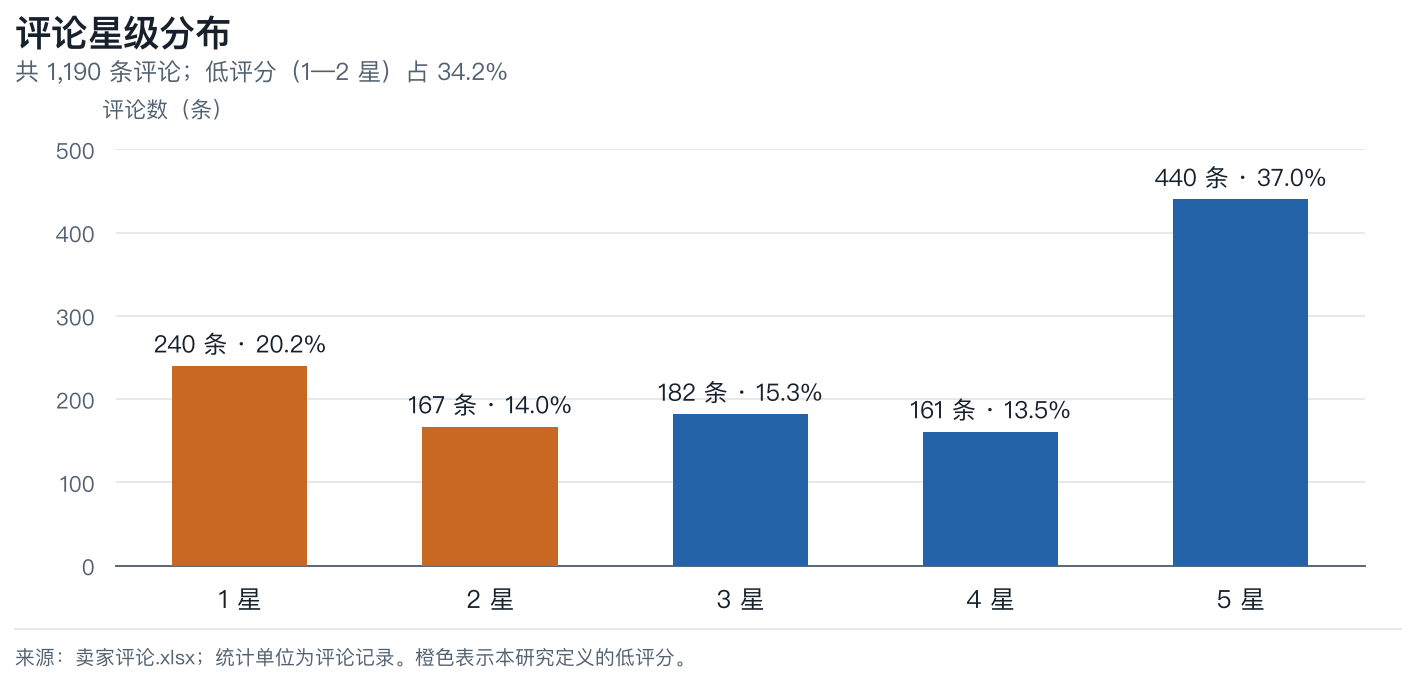

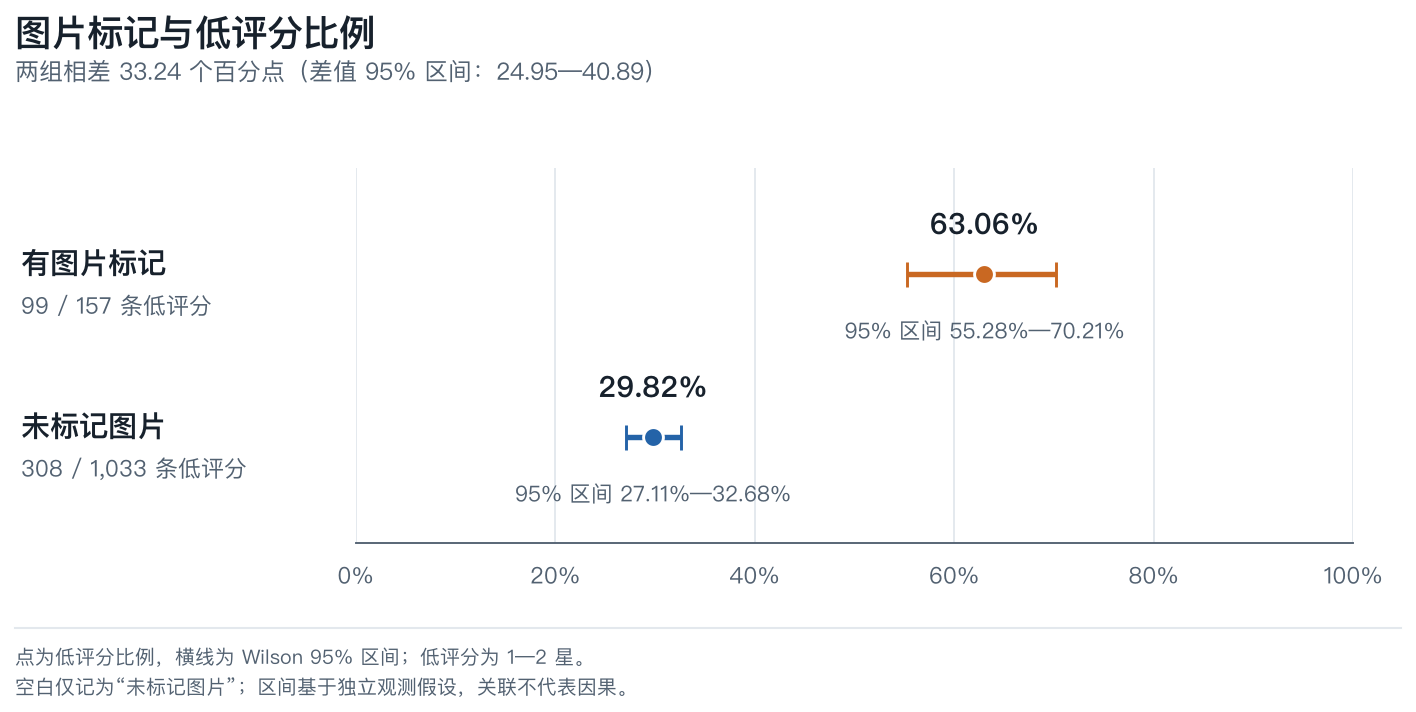

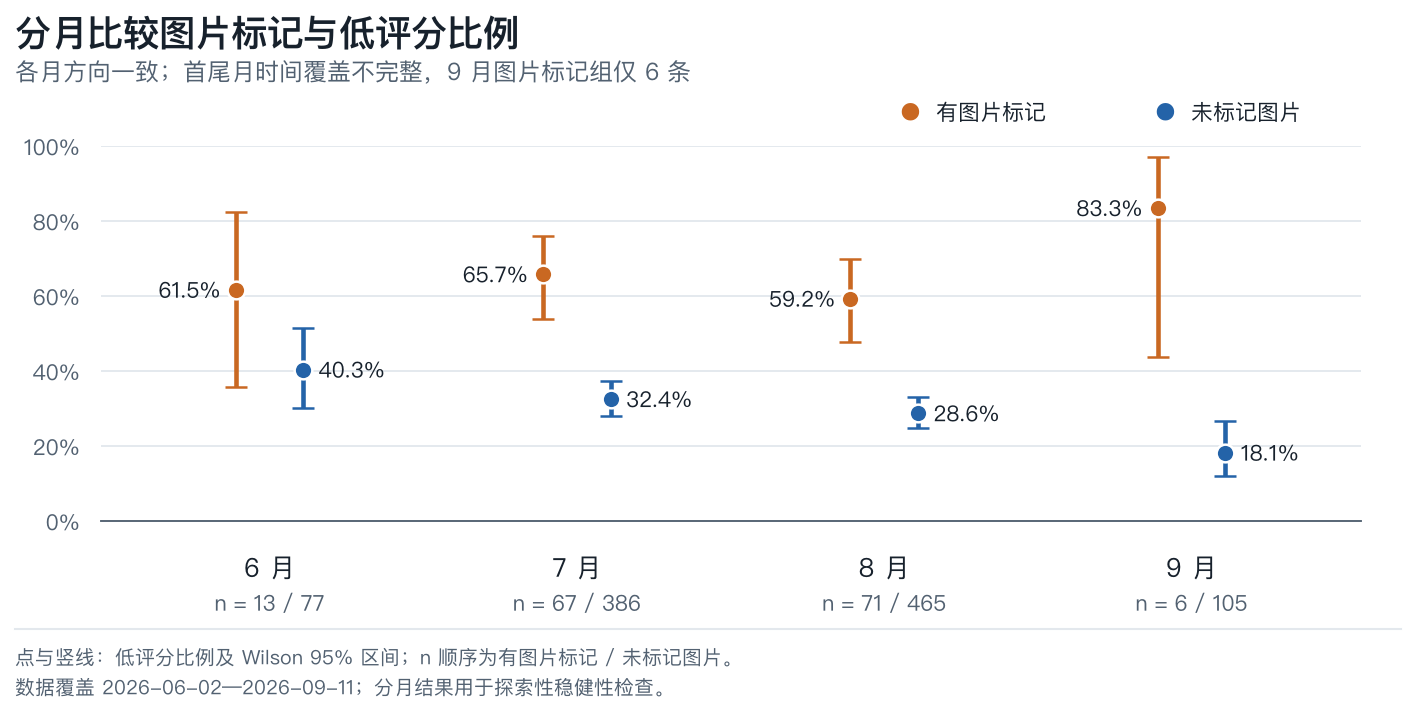

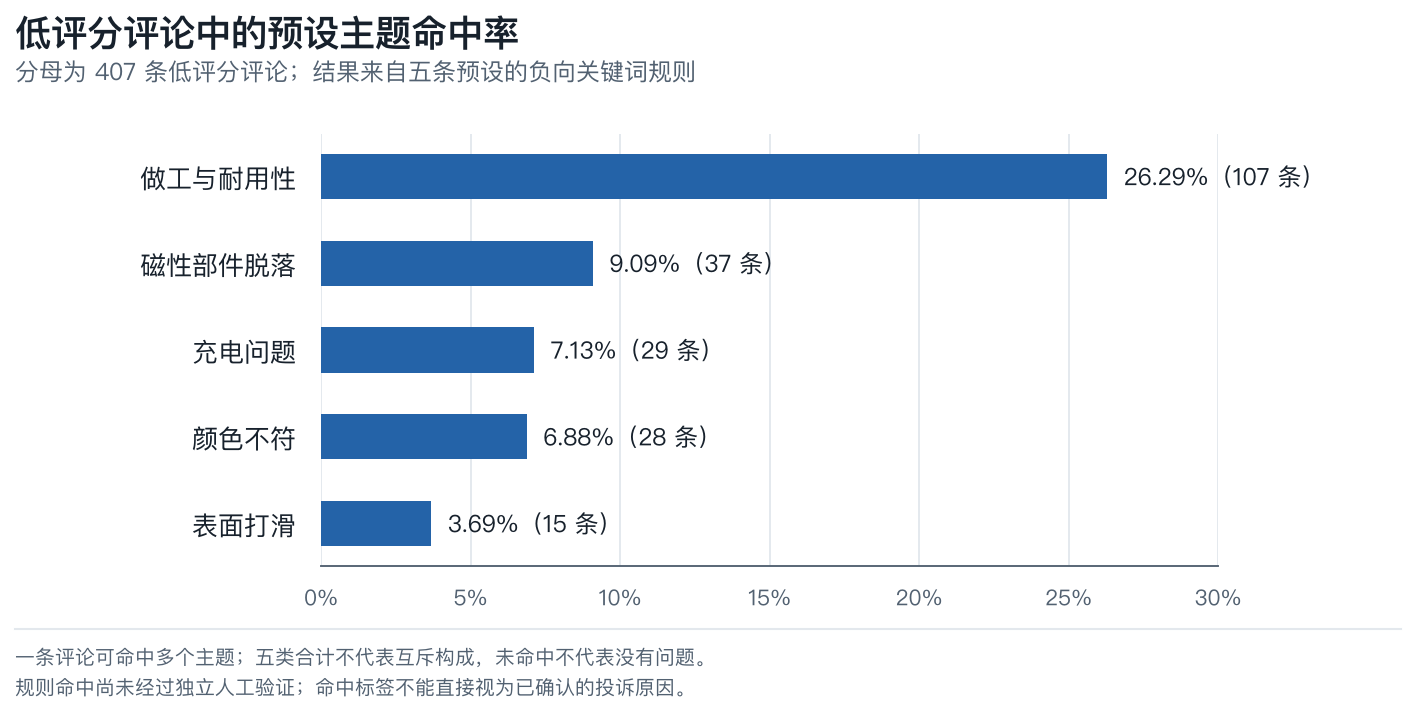

In [22]:
def create_report_canvas(title, subtitle):
    '''复刻 1000x500 画布布局、主副标题与页脚分隔线。'''
    fig, ax = plt.subplots(figsize=(10, 5), dpi=150)
    fig.patch.set_facecolor(PALETTE["WHITE"])
    ax.set_facecolor(PALETTE["WHITE"])

    # 主标题与副标题（与原图左上对齐位置一致）
    fig.text(0.038, 0.925, title, fontsize=17.5, fontweight="bold", color=PALETTE["BLACK"], ha="left", va="top")
    fig.text(0.038, 0.865, subtitle, fontsize=11.5, color=PALETTE["GRAY"], ha="left", va="top")

    # 隐藏顶部与右侧边框，保留底部主轴线
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(PALETTE["GRAY"])
    ax.spines["bottom"].set_linewidth(0.9)
    return fig, ax

def add_report_footer(fig, line1, line2=None):
    '''复刻底部浅灰分隔线与双行注释。'''
    sep = plt.Line2D([0.038, 0.962], [0.106, 0.106], transform=fig.transFigure, color=PALETTE["GRID"], linewidth=1.0)
    fig.add_artist(sep)
    fig.text(0.038, 0.068, line1, fontsize=9.5, color=PALETTE["GRAY"], ha="left", va="center")
    if line2:
        fig.text(0.038, 0.028, line2, fontsize=9.5, color=PALETTE["GRAY"], ha="left", va="center")

def save_and_show(fig, filename):
    fig.savefig(CHART_DIR / f"{filename}.png", dpi=200, facecolor=PALETTE["WHITE"])
    fig.savefig(CHART_DIR / f"{filename}.svg", facecolor=PALETTE["WHITE"])
    plt.show()

# ==================== 图 1：评论星级分布 ====================
def plot_stars(data):
    n = data["overall"]["n"]
    low = data["overall"]["rate"]
    fig, ax = create_report_canvas("评论星级分布", f"共 {n:,} 条评论；低评分（1—2 星）占 {low:.1%}")
    fig.subplots_adjust(left=0.105, right=0.938, bottom=0.19, top=0.745)

    stars_list = data["stars"]
    x = np.arange(len(stars_list))
    counts = [item["count"] for item in stars_list]
    shares = [item["share"] for item in stars_list]
    colors = [PALETTE["ORANGE"] if item["star"] <= 2 else PALETTE["BLUE"] for item in stars_list]

    bars = ax.bar(x, counts, width=0.54, color=colors, zorder=3)
    ax.set_ylim(0, 500)
    ax.set_yticks(range(0, 501, 100))
    ax.tick_params(axis="y", length=0, pad=10, labelsize=10.5, colors=PALETTE["GRAY"])
    ax.yaxis.grid(True, color=PALETTE["GRID"], linewidth=0.9, zorder=0)
    ax.set_axisbelow(True)

    ax.set_xticks(x)
    ax.set_xticklabels([f"{item['star']} 星" for item in stars_list], fontsize=12, color=PALETTE["BLACK"])
    ax.tick_params(axis="x", length=0, pad=10)
    ax.text(-0.55, 535, "评论数（条）", fontsize=10.5, color=PALETTE["GRAY"], ha="left", va="bottom")

    for bar, c, s in zip(bars, counts, shares):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            c + 12,
            f"{c} 条 · {s:.1%}",
            ha="center",
            va="bottom",
            fontsize=11.5,
            color=PALETTE["BLACK"],
        )

    add_report_footer(fig, "来源：卖家评论.xlsx；统计单位为评论记录。橙色表示本研究定义的低评分。")
    save_and_show(fig, "01_星级分布")

# ==================== 图 2：图片标记与低评分比例 ====================
def plot_image_compare(data):
    s = data["main"]
    diff = s["difference"] * 100
    ci = [v * 100 for v in s["difference_newcombe95"]]
    fig, ax = create_report_canvas(
        "图片标记与低评分比例",
        f"两组相差 {diff:.2f} 个百分点（差值 95% 区间：{ci[0]:.2f}—{ci[1]:.2f}）"
    )
    fig.subplots_adjust(left=0.265, right=0.930, bottom=0.22, top=0.72)

    ax.set_xlim(0, 1.0)
    ax.set_ylim(0.2, 2.5)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_xticklabels([f"{v}%" for v in range(0, 101, 20)], fontsize=11, color=PALETTE["GRAY"])
    ax.tick_params(axis="x", length=0, pad=10)
    ax.xaxis.grid(True, color=PALETTE["GRID"], linewidth=0.9, zorder=0)
    ax.set_yticks([])

    groups = [
        ("有图片标记", "image", 0, 1.85, PALETTE["ORANGE"]),
        ("未标记图片", "unmarked", 1, 0.85, PALETTE["BLUE"]),
    ]
    for label, key, row_idx, y, color in groups:
        val = s[f"{key}_rate"]
        lo, hi = s[f"{key}_wilson95"]
        k = sum(s["table"][row_idx])
        cnt = s["table"][row_idx][0]

        fig.text(0.042, 0.22 + (y - 0.2) / 2.3 * 0.50 + 0.015, label, fontsize=14, fontweight="bold", color=PALETTE["BLACK"], ha="left", va="center")
        fig.text(0.042, 0.22 + (y - 0.2) / 2.3 * 0.50 - 0.042, f"{cnt} / {k:,} 条低评分", fontsize=11, color=PALETTE["GRAY"], ha="left", va="center")

        ax.errorbar(
            val, y,
            xerr=[[val - lo], [hi - val]],
            fmt="o",
            color=color,
            ecolor=color,
            elinewidth=2.6,
            capsize=6,
            capthick=2.6,
            markersize=9.5,
            markeredgecolor=PALETTE["WHITE"],
            markeredgewidth=1.4,
            zorder=4,
        )
        ax.text(val, y + 0.22, f"{val:.2%}", fontsize=14, fontweight="bold", color=PALETTE["BLACK"], ha="center", va="bottom")
        ax.text(val, y - 0.28, f"95% 区间 {lo:.2%}—{hi:.2%}", fontsize=10.5, color=PALETTE["GRAY"], ha="center", va="top")

    add_report_footer(
        fig,
        "点为低评分比例，横线为 Wilson 95% 区间；低评分为 1—2 星。",
        "空白仅记为“未标记图片”；区间基于独立观测假设，关联不代表因果。"
    )
    save_and_show(fig, "02_图片标记与低评分")

# ==================== 图 3：分月比较图片标记与低评分比例 ====================
def plot_monthly(data):
    fig, ax = create_report_canvas(
        "分月比较图片标记与低评分比例",
        "各月方向一致；首尾月时间覆盖不完整，9 月图片标记组仅 6 条"
    )
    fig.subplots_adjust(left=0.095, right=0.935, bottom=0.25, top=0.75)

    months = list(data["monthly"].keys())
    x_centers = np.arange(len(months))
    ax.set_xlim(-0.55, len(months) - 0.45)
    ax.set_ylim(0, 1.0)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_yticklabels([f"{v}%" for v in range(0, 101, 20)], fontsize=10.5, color=PALETTE["GRAY"])
    ax.tick_params(axis="y", length=0, pad=10)
    ax.yaxis.grid(True, color=PALETTE["GRID"], linewidth=0.9, zorder=0)
    ax.set_xticks([])

    # 右上角自定义图例
    fig.text(0.635, 0.795, "●", fontsize=11, color=PALETTE["ORANGE"], ha="center", va="center")
    fig.text(0.652, 0.795, "有图片标记", fontsize=10.5, color=PALETTE["BLACK"], ha="left", va="center")
    fig.text(0.805, 0.795, "●", fontsize=11, color=PALETTE["BLUE"], ha="center", va="center")
    fig.text(0.822, 0.795, "未标记图片", fontsize=10.5, color=PALETTE["BLACK"], ha="left", va="center")

    for i, month in enumerate(months):
        s = data["monthly"][month]
        for key, offset, color in [("image", -0.11, PALETTE["ORANGE"]), ("unmarked", 0.11, PALETTE["BLUE"])]:
            val = s[f"{key}_rate"]
            lo, hi = s[f"{key}_wilson95"]
            xp = x_centers[i] + offset
            ax.errorbar(
                xp, val,
                yerr=[[val - lo], [hi - val]],
                fmt="o",
                color=color,
                ecolor=color,
                elinewidth=2.2,
                capsize=5.5,
                capthick=2.2,
                markersize=8.5,
                markeredgecolor=PALETTE["WHITE"],
                markeredgewidth=1.2,
                zorder=4,
            )
            ax.text(
                xp + (-0.05 if offset < 0 else 0.05),
                val,
                f"{val:.1%}",
                fontsize=10.5,
                color=PALETTE["BLACK"],
                ha="right" if offset < 0 else "left",
                va="center",
            )
        ns = [sum(row) for row in s["table"]]
        ax.text(x_centers[i], -0.09, f"{int(month[-2:])} 月", fontsize=12.5, color=PALETTE["BLACK"], ha="center", va="top")
        ax.text(x_centers[i], -0.19, f"n = {ns[0]} / {ns[1]}", fontsize=10.5, color=PALETTE["GRAY"], ha="center", va="top")

    add_report_footer(
        fig,
        "点与竖线：低评分比例及 Wilson 95% 区间；n 顺序为有图片标记 / 未标记图片。",
        "数据覆盖 2026-06-02—2026-09-11；分月结果用于探索性稳健性检查。"
    )
    save_and_show(fig, "03_分月比较")

# ==================== 图 4：低评分评论中的预设主题命中率 ====================
def plot_themes(data):
    fig, ax = create_report_canvas(
        "低评分评论中的预设主题命中率",
        "分母为 407 条低评分评论；结果来自五条预设的负向关键词规则"
    )
    fig.subplots_adjust(left=0.242, right=0.840, bottom=0.19, top=0.765)

    themes_list = data["negative_themes"][::-1]  # 反转使最高命中率排在最上方
    y = np.arange(len(themes_list))
    shares = [item["share"] for item in themes_list]
    counts = [item["count"] for item in themes_list]
    labels = [item["topic"] for item in themes_list]

    bars = ax.barh(y, shares, height=0.52, color=PALETTE["BLUE"], zorder=3)
    ax.set_xlim(0, 0.30)
    ax.set_xticks(np.linspace(0, 0.30, 7))
    ax.set_xticklabels([f"{v}%" for v in range(0, 31, 5)], fontsize=10.5, color=PALETTE["GRAY"])
    ax.tick_params(axis="x", length=0, pad=10)
    ax.xaxis.grid(True, color=PALETTE["GRID"], linewidth=0.9, zorder=0)

    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=12.5, color=PALETTE["BLACK"])
    ax.tick_params(axis="y", length=0, pad=12)

    for bar, s_val, c_val in zip(bars, shares, counts):
        ax.text(
            s_val + 0.0055,
            bar.get_y() + bar.get_height() / 2,
            f"{s_val:.2%}（{c_val} 条）",
            fontsize=11.5,
            color=PALETTE["BLACK"],
            ha="left",
            va="center",
        )

    add_report_footer(
        fig,
        "一条评论可命中多个主题；五类合计不代表互斥构成，未命中不代表没有问题。",
        "规则命中尚未经过独立人工验证；命中标签不能直接视为已确认的投诉原因。"
    )
    save_and_show(fig, "04_低星主题")

# 依次绘制并保存四张图表
plot_stars(STATS_DATA)
plot_image_compare(STATS_DATA)
plot_monthly(STATS_DATA)
plot_themes(STATS_DATA)